In [1]:
from IPython.display import HTML
HTML("""<style>
@page { size: letter; margin: 11mm 13mm; }
body { margin: 0 !important; }
.jp-Notebook { padding: 0 !important; }
.jp-Cell { padding: 0 !important; margin: 0 !important; }
.jp-InputPrompt, .jp-OutputPrompt { display: none !important; }
.jp-RenderedHTMLCommon { font-size: 8.6pt !important; line-height: 1.32 !important; padding-right: 0 !important; }
.jp-RenderedHTMLCommon h1 { font-size: 14pt !important; margin: 0 0 3px 0 !important; }
.jp-RenderedHTMLCommon h2 { font-size: 11pt !important; margin: 7px 0 3px 0 !important; }
.jp-RenderedHTMLCommon p { margin: 0 0 4px 0 !important; }
.jp-RenderedHTMLCommon ul, .jp-RenderedHTMLCommon ol { margin: 0 0 4px 0 !important; padding-left: 16px !important; }
.jp-RenderedHTMLCommon li { margin: 0 0 1px 0 !important; }
.jp-RenderedHTMLCommon table { font-size: 7.6pt !important; margin: 2px 0 5px 0 !important; }
.jp-RenderedHTMLCommon td, .jp-RenderedHTMLCommon th { padding: 1px 5px !important; }
.jp-RenderedHTMLCommon code { font-size: 8pt !important; }
.jp-OutputArea-output img { margin: 0 auto; display: block; }
</style>""")

# EE 513 Project 1: Measured Datasheet, iPhone 16 Pro Max Main Camera
**Jon Knapp** · EE 513 Intro to Image Processing · November 2026

**Repository:** https://github.com/Jon-Knapp/EE513

**Resume line:** _______________________________________________

_Contents: datasheet report (Sections 1 to 6), then the one-page decisions-and-verification statement._

In [2]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

R = json.loads(Path("results.json").read_text(encoding="utf-8"))
C = json.loads(Path("project1_checks.json").read_text(encoding="utf-8"))

def show(path, width):
    display(Image(filename=path, width=width))

def pm(key, fmt="{:.3g}"):
    v = R[key]
    if v is None:
        return "not measured (see §3)"
    return f"{fmt.format(v[0])} ± {fmt.format(v[1])}"

## 1. Device under test

| | |
|---|---|
| Camera | `iPhone 16 Pro Max back camera 6.765mm f/1.78` (EXIF LensModel), the main camera at 1x, no zoom |
| Raw format | Bayer DNG, 4032 × 3024, **BGGR**, 12-bit (black 528 DN, white 4095 DN in the file) |
| Sensor | 48 MP quad-pixel sensor: the 12 MP raw is **2 × 2 binned**, so one output pixel is 2.44 µm (Apple) against a 1.22 µm photodiode. Every number below is per **output** pixel. |
| Capture app | Halide Mark III - Pro Camera v3.3.3 |
| Camera check | The `lens_id` assertion from the project page passes on every series: 25 calibration, 6 slanted-edge, 20 flat-field, 23 dark and 12 color captures. All five return the same LensModel, 6.765 mm, 24 mm equivalent and 4032 × 3024. |

**Uncertainty conventions.** "s.d." is the standard deviation over repeated captures; "jackknife" is the leave-one-view-out standard error of the calibration; "fit" is the 1σ from the fit's covariance; a "bound" is stated with its argument in the text.

## 2. Datasheet

In [3]:
rows = [
 ("Geometry", "Focal length", pm("focal_length_px", "{:.1f}") + " px", "jackknife, 25 views, 5-coef. model"),
 ("", "Focal length", pm("focal_length_mm", "{:.2f}") + " mm", "f_px × EXIF-route pitch 2.422 µm; bound from 24 mm-equiv. rounding"),
 ("", "Principal point (x, y)", f"{pm('principal_point_x_px', '{:.1f}')}, {pm('principal_point_y_px', '{:.1f}')} px", "jackknife"),
 ("", "Radial k1, k2, k3", f"{pm('distortion_k1')}, {pm('distortion_k2')}, {pm('distortion_k3')}", "jackknife"),
 ("", "Tangential p1, p2", f"{pm('distortion_p1', '{:.2g}')}, {pm('distortion_p2', '{:.2g}')}", "jackknife"),
 ("", "RMS reprojection error", pm("reprojection_rms_px", "{:.3f}") + " px", "jackknife"),
 ("Resolution", "MTF50, centre", pm("mtf50_center_cy_per_px", "{:.3f}") + " cy/green px", "s.d., 6 captures; Nyquist = 0.5"),
 ("", "MTF at green Nyquist, centre", "0.404 ± 0.032", "s.d., 6 captures (predicted 0.785)"),
 ("", "MTF50, corner squares (32% field)", "{:.3f} ± {:.3f} cy/green px".format(*C["mtf"]["corner_squares_mean"]), "s.d., 6 captures; not the frame corners"),
 ("", "Corner-square / centre MTF50", "{:.3f} ± {:.3f}".format(*C["mtf"]["corner_over_centre"]), "s.d. of the per-capture ratio"),
 ("Noise (ISO 50)", "Conversion gain K", pm("conversion_gain_dn_per_e", "{:.3f}") + " DN/e⁻", "fit ± fit-range systematic, in quadrature"),
 ("", "Read noise", pm("read_noise_e", "{:.1f}") + " e⁻  (1.694 ± 0.002 DN)", "dark-frame pairs; gain uncertainty propagated"),
 ("", "Full well (clip level)", "14,500 ± 1,200 e⁻", "3567 DN / K"),
 ("", "Shot/read-noise knee", "47 ± 8 e⁻", "σr², from the read noise above"),
 ("", "Dark current", "< 0.6 e⁻/s (95%)", "upper bound, 23 capped frames, 1/30 to 1 s"),
 ("", "Black level", pm("black_level_dn", "{:.1f}") + " DN (file: 528)", "1/30 s dark frames, spread between channels"),
 ("Dynamic range", "Full scale / read noise", pm("dynamic_range_stops", "{:.2f}") + " stops", "bound from the effective white level"),
 ("Color (LED)", "Mean ΔE00 before CCM", pm("delta_e_mean_before_ccm", "{:.2f}"), "s.d. over 3 charts"),
 ("", "Mean ΔE00 after CCM", pm("delta_e_mean_after_ccm", "{:.2f}"), "s.d. over 3 charts"),
 ("", "Worst patch after CCM", pm("delta_e_worst_after_ccm", "{:.2f}") + " (15, red)", "s.d. over 3 charts"),
]
df = pd.DataFrame(rows, columns=["", "Quantity", "Value", "Uncertainty from"])
display(df.style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "7.6pt"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left"), ("font-size", "7.6pt")]}]))

,Quantity,Value,Uncertainty from
Geometry,Focal length,2901.8 ± 4.6 px,"jackknife, 25 views, 5-coef. model"
,Focal length,7.03 ± 0.15 mm,f_px × EXIF-route pitch 2.422 µm; bound from 24 mm-equiv. rounding
,"Principal point (x, y)","2026.1 ± 4.3, 1510.0 ± 4.4 px",jackknife
,"Radial k1, k2, k3","0.232 ± 0.008, -0.946 ± 0.038, 1.07 ± 0.063",jackknife
,"Tangential p1, p2","0.001 ± 0.00051, -0.00075 ± 0.00062",jackknife
,RMS reprojection error,0.863 ± 0.029 px,jackknife
Resolution,"MTF50, centre",0.403 ± 0.032 cy/green px,"s.d., 6 captures; Nyquist = 0.5"
,"MTF at green Nyquist, centre",0.404 ± 0.032,"s.d., 6 captures (predicted 0.785)"
,"MTF50, corner squares (32% field)",0.275 ± 0.022 cy/green px,"s.d., 6 captures; not the frame corners"
,Corner-square / centre MTF50,0.681 ± 0.010,s.d. of the per-capture ratio


**Against the manufacturer.**

* **Pixel pitch.** Apple gives 2.44 µm for the binned pixel. The EXIF crop-factor route gives 2.422 µm (−0.7%). The calibration route, 1000 · 6.765 mm / f_px, gives 2.331 µm (−4.5%).
* **Focal length.** The calibrated focal length, 7.03 ± 0.15 mm, is 3.9% above the EXIF 6.765 mm. I believe most of that gap is focus breathing rather than an error. The calibration measures the lens-to-sensor distance at the focus it was shot at, and the board sat 234 to 365 mm away (median 296 mm, from the calibration extrinsics). For a 6.765 mm thin lens that adds 1.9% to 3.0%, which leaves the remainder inside the pitch bound. The same effect explains why route 1 of the pitch comes out low.
* **NoiseProfile.** Apple's own noise model in the DNG converts to K = 0.316 DN/e⁻ and σr = 11.2 e⁻ (3.54 DN). Mine are 22% and 52% lower (see §4).

## 3. Geometry and spatial resolution

**Calibration.** I used `cv2.calibrateCamera` on 25 views of a 9 × 6 board (20.0 mm squares), all 25 detected. Eight of them deliberately put the board near the frame edges and corners. With four coefficients (k1, k2, p1, p2) the RMS reprojection error is 1.44 px. Adding k3 brings it to **0.86 ± 0.03 px**, so I adopt the five-coefficient model.

The fit's own 1σ understates the real uncertainty by a factor of 3 to 6. For example, the principal point is ±1.3 px from the fit against ±4.3 px from the jackknife. The reason is that the board is not flat: a plain homography leaves 2.2 px median residuals on every view. So the datasheet quotes the jackknife throughout.

The corners reach 78% of the way to the frame corner (normalized radius 0.676 of 0.872), so the model is extrapolated in the outer 22%. On the board row furthest from the principal point (48% of the half-diagonal), the maximum deviation from a straight line falls from 1.35 px to 0.69 px after undistortion. The median over all 150 rows falls from 1.36 px to 0.52 px.

| Model | f (px) | c_x, c_y (px) | k1 | k2 | p1 | p2 | k3 | RMS (px) |
|---|---|---|---|---|---|---|---|---|
| 4 coefficients | 2914.6 ± 6.2 | 2030.7 ± 12.3, 1515.4 ± 9.6 | 0.114 ± 0.012 | −0.268 ± 0.031 | 0.0017 ± 0.0013 | −0.0000 ± 0.0014 | 0 (fixed) | 1.44 ± 0.11 |
| **5 coefficients (adopted)** | **2901.8 ± 4.6** | **2026.1 ± 4.3, 1510.0 ± 4.4** | **0.232 ± 0.008** | **−0.946 ± 0.038** | **0.0010 ± 0.0005** | **−0.0007 ± 0.0006** | **1.070 ± 0.063** | **0.86 ± 0.03** |

The tangential terms are within 2σ of zero in both models. The principal point is 10.6 px right of and 1.5 px above the geometric centre (2015.5, 1511.5), within about 2.5σ and 0.3σ of it.

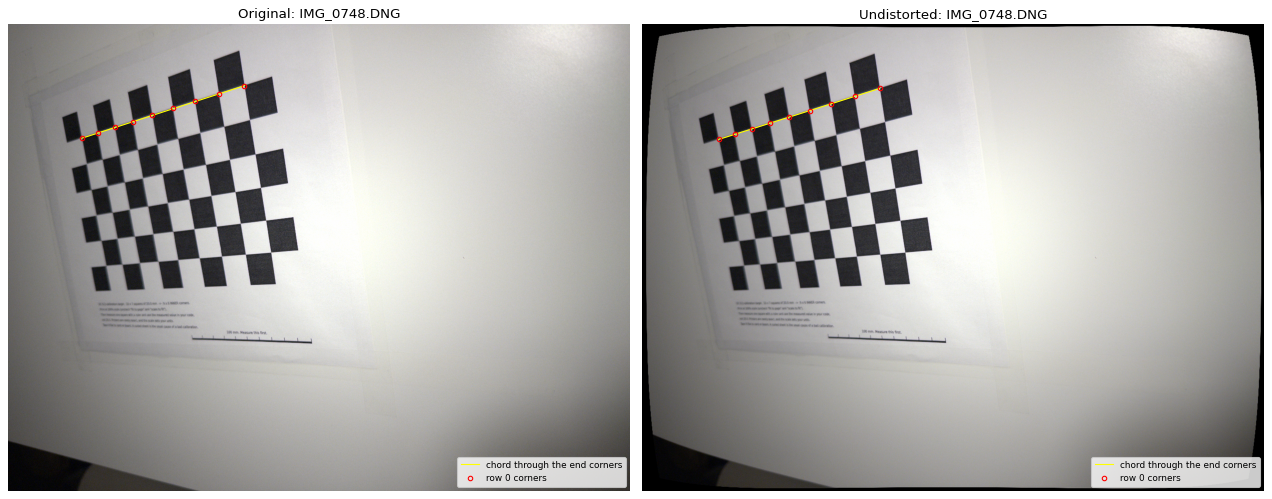

In [4]:
show("figures/p1_undistort.png", 600)

_Figure 1: the original frame and the frame undistorted with the five-coefficient model. The red circles are row 0 of the board, the straight row furthest from the principal point; the yellow chord joins its end corners._

**MTF.** I used the slanted-edge method (ISO 12233 style) on one black-subtracted green plane of the Bayer mosaic. One green-plane pixel is 2p = 4.84 µm, so **Nyquist is 0.5 cycles per green-plane pixel, and that is the unit used throughout**; per full-mosaic pixel, halve every value. The code was first checked on a synthetic Gaussian edge with a known MTF50: it was off by −0.12% at σ = 1 px, and by under 0.7% across other blur widths, edge angles and added noise.

* **Centre.** MTF50 is **0.403 ± 0.032 cy/green px**, which is 0.81 of Nyquist (0.0833 ± 0.0066 cycles/µm). The MTF at Nyquist is 0.404 ± 0.032. The ± is the s.d. over 6 captures, each the mean of 4 edges.
* **Against the prediction.** Diffraction (f/1.78, 550 nm) × the photodiode aperture predicted an MTF50 of 0.959 cy/green px and 0.785 at Nyquist. The measured curve keeps only about half of that. The prediction omits lens aberrations, defocus, crosstalk and the printed edge. Aberrations are the leading suspect because the loss grows away from the axis, as the corner squares show.
* **Corners.** The target's corner squares sit at 32 to 33% of the half-diagonal. There, MTF50 is 0.306 ± 0.022 (top-left), 0.258 ± 0.024 (top-right) and 0.260 ± 0.021 (bottom-right). The bottom-left square was not detected. Their mean is **0.275 ± 0.022**, and the corner-to-centre ratio is **0.681 ± 0.010**. That ratio is far steadier than either number alone, because capture-to-capture focus changes move all squares together.
* **Not measured.** MTF50 at the **frame corners** needs captures with the target placed in each corner of the frame. Those values are `null` in results.json rather than standing in the 32%-field values for them.

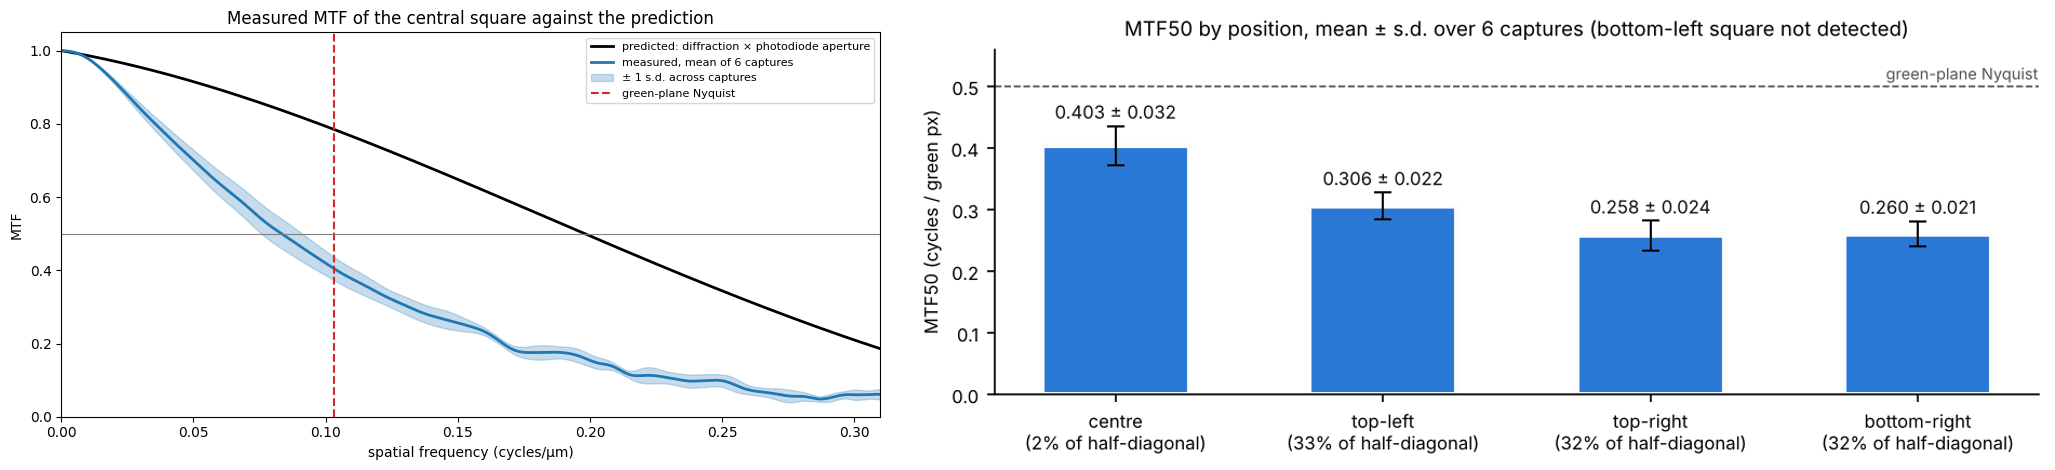

In [5]:
show("figures/p1_mtf_and_field.png", 720)

_Figure 2: the measured centre MTF against the prediction (left), and MTF50 by position on the target (right)._

## 4. Noise: the Poisson-Gaussian model (ISO 50)

**Captures and method.** I took 10 flat-field pairs from 0.9% to 96% of saturation. The light source was an overcast window through 2 to 10 sheets of paper, at exposures from 1/30 to 1 s. Each statistic comes from a 128 × 128 patch at the centre of one green plane.

For each pair, the mean is the average of the two frame means minus the black level. The variance is ½ Var(A − B). The fit is Var = K·μ + K²σr², weighted by 1/variance, through the 9 pairs below 70% of saturation. **1/12 DN² of rounding is removed from the intercept before taking σr.**

**Why pairs and not single frames.** A single frame's variance also contains the fixed pixel-to-pixel sensitivity pattern (PRNU), which grows as (p·μ)². It bends the line upward and inflates the slope. Fitting single frames gave K = 0.281 ± 0.021 DN/e⁻, **14.3% high**, and the excess fits p = 0.61% PRNU. The same code recovers the simulator's PRNU as 1.18% against its true 1.20%. The difference of two frames cancels the pattern exactly.

* **Gain.** K = **0.246 ± 0.021 DN/e⁻** (1/K = 4.06 e⁻/DN). The fit gives ±0.014. A further ±0.015 comes from the fit range, because K is 0.218 below 15% of saturation, 0.229 below 30% and 0.246 below 70%: variance/mean rises with signal, which a sensor that followed the model would not do. The two are combined in quadrature.
* **Read noise.** The fit intercept constrains it poorly (4.2 ± 2.9 e⁻), so I measured it directly from 11 pairs of dark frames: **1.694 ± 0.002 DN = 6.9 ± 0.6 e⁻**, within 1.3σ of the fit. This is the noise per binned output pixel. A per-photodiode figure would be different and is not comparable.
* **SNR and regimes.** The photon-limited and read-noise-limited regimes meet at μ = σr² = **47 ± 8 e⁻** (11.7 DN above black). Measured SNR follows the model within a median of 6%. My darkest pair is at 135 e⁻, 2.9× above the knee, so the captures show the start of the bend but not the read-noise regime itself.
* **Vendor NoiseProfile.** The tag is present: S = 8.858 × 10⁻⁵, O = 9.874 × 10⁻⁷, in normalized units. Carried through 3567 DN, it gives K = 0.316 DN/e⁻ and σr = 3.54 DN (11.2 e⁻). It matches my measured variance at 54% of saturation (ratio 0.99), but it overstates the variance increasingly toward black, by 2.3× at the darkest pair. It behaves like a conservative model for noise reduction rather than a measurement of this sensor at ISO 50.
* **Dark current.** I fitted 23 lens-capped frames at 1/30, 1/4, 1/2 and 1 s. The green slope is 0.082 ± 0.015 DN/s (0.33 e⁻/s at face value), but I do not treat it as a measurement, for three reasons. The four Bayer channels disagree beyond their errors (0.077 to 0.134 DN/s). The level jumps by up to 0.09 DN between frames at a fixed exposure, which is as large as the whole trend. And exposure order matched time order, so a drifting offset would look the same. Reported value: **< 0.6 e⁻/s** (one-sided 95%, steepest channel). At the app's 1 s maximum, that adds less than 1.3% to the read-noise variance. The phone was at room temperature.

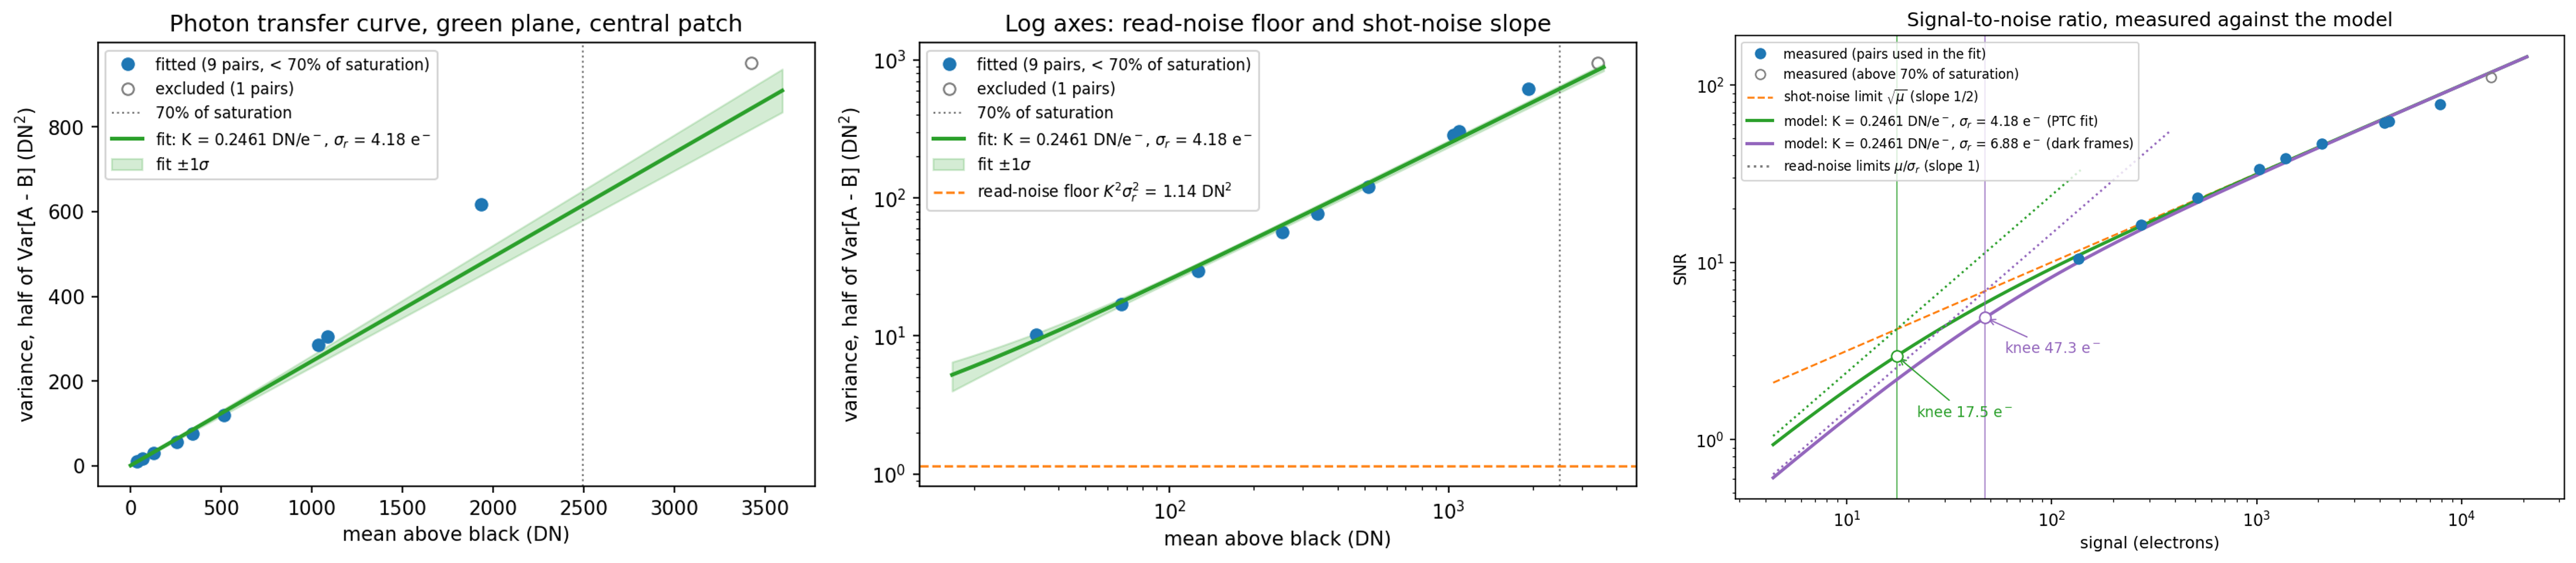

In [6]:
show("figures/p1_ptc_and_snr.png", 720)

_Figure 3: the photon transfer curve, central patch of the green plane (left), and measured SNR against the model, with the knee marked (right)._

## 5. Dynamic range

**DR = log2(3567 DN / 1.694 DN) = 11.04 ± 0.06 stops.** The criterion: the low end is the signal equal to the read noise (SNR = 1 from read noise alone), and the top is white level minus black level. In DN the ratio does not depend on the gain at all. The statistical uncertainty is 0.002 stops.

The ± is a bound instead. The green sites start to saturate near 3950 DN, not 4095 (found in the ISO 400 color captures), and that full scale would give 10.98 stops. Other conventions give 10.9 stops (EMVA 1288: SNR = 1 including the signal's own shot noise) and 6.7 stops (SNR = 10).

## 6. Color accuracy

I took three ColorChecker Classic Mini charts under an LED lamp, ISO 400, 1/60 s, with no clipped patches. Processing was per chart:

1. Black subtraction and normalization to the measured saturation level (3940 DN).
2. Quarter-resolution RGB without demosaicing.
3. Per-channel lens-shading correction from a white sheet in the same round.
4. Means from the middle half of each patch.
5. White balance from patch 22 (neutral 5).
6. A 3 × 3 matrix to XYZ by least squares over all 24 patches.

**Metric:** CIEDE2000, with the measured white patch as the CIELAB white. **Reference:** colour-science's `ColorChecker24 - After November 2014`. I chose it because X-Rite reformulated the chart in November 2014, and I assume the class charts were made after that change (not verified).

* **Before the matrix**, treating balanced camera RGB as linear sRGB: mean ΔE00 **12.35 ± 0.08**.
* **After the matrix:** mean **3.06 ± 0.04**. The worst patch is **15 red, 8.89 ± 0.26**, followed by 13 blue and 7 orange.

The ± is the s.d. over the three charts. The charts agree to about 1%, so the 3.06 belongs to the camera and the 3 × 3 model, not to the charts.

The residual stays because the sensor's spectral sensitivities are not a linear combination of the CIE color-matching functions (the Luther condition fails). The error therefore gathers on saturated patches whose spectra change steeply at the ends of the visible range.

Carried unchanged to other lights, with only the white balance refitted, the LED matrix gives 5.79 under a blackbody lamp of similar CCT and 6.94 under daylight. So one stored matrix is not correct under every light.

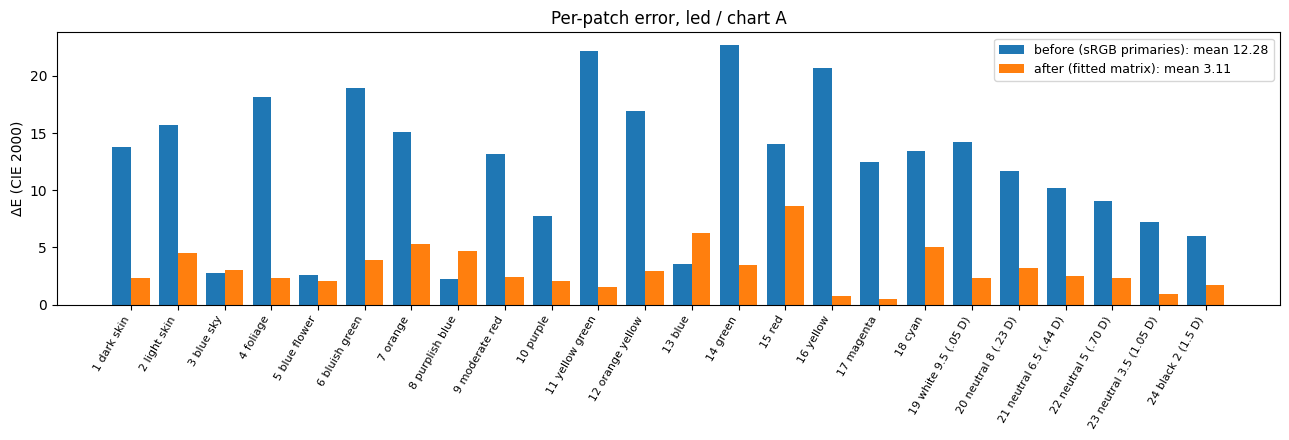

In [7]:
show("figures/p1_deltaE_per_patch.png", 560)

_Figure 4: ΔE00 per patch before and after the matrix (LED, chart A)._

<div style="page-break-before: always;"></div>

## Decisions and verification statement

**What I decided, and what I rejected.**

* **Five distortion coefficients, not four.** The board positions near the corners pushed the four-coefficient RMS to 1.44 px. With k3 it is 0.86 px. I rejected the 2.33 µm calibration-route pixel pitch for the EXIF route (2.42 µm), because the calibration's focal length is inflated by close focus.
* **MTF on one green plane** of the raw mosaic, never on demosaiced data, so no interpolation enters the edge.
* **Read noise from dark-frame pairs, not the PTC intercept.** The intercept is an extrapolation with ±69% uncertainty.
* **Dark current reported as an upper bound, not the 0.33 e⁻/s fit.**
* **Saturation at 3940 DN, not the declared 4095.** The 4095 white level was not trusted, because the green sites pile up from about 3950 DN. That excluded seven blackbody patches and made the LED round the primary color round.
* **Frame-corner MTF left `null`** in results.json rather than standing in the 32%-field values.

**AI use.** I used Claude (Anthropic) to write most of the analysis code in the four homework notebooks, to diagnose problems in my captures, to explain concepts, and to draft written answers, which I reviewed and edited. Claude also assembled this report and results.json from those notebooks, and wrote `project1_checks.py`, which adds the jackknife calibration uncertainties and the corner-square MTF.

**How I checked the results.**

* **Known answers before real data.**
    * The slanted-edge code recovered a synthetic σ = 1 px Gaussian edge's MTF50 to −0.12%.
    * The PTC code, on the lecture 5 simulator, recovered K to −0.04% ± 0.21% and σr to +0.30% ± 0.70% over 20 independent runs.
    * The sRGB encode/decode passes a round trip to 1e-12.
* **Failure modes I found and fixed.**
    * My first read-noise fit on the simulator was **+5.2% (8σ) high**. The cause was the 1/12 DN² that rounding adds to every variance. With it subtracted, the bias is gone.
    * My first calibration (32 views of a target that was not flat) gave 1.23 px RMS. Re-shot on a rigid board, a homography-only test still shows 2.2 px median residuals, so flatness, not the code, limits the RMS.
    * A fixed 11 px corner-refinement window failed on defocused close-range boards. I made it scale with the square size.
    * The slanted-edge target took four capture sessions before repeated photos agreed. The earlier sessions showed close-range defocus and off-centre framing.
* **Independent cross-checks.**
    * Pixel pitch two ways, against Apple's 2.44 µm.
    * Read noise from the fit against the dark frames (1.3σ apart).
    * Single-frame against pair gain. The +14.3% matches the +14.2% the simulator gives for a known PRNU.
    * Color across three physical charts (3.03 to 3.11).
    * Re-running the Homework 2 functions inside `project1_checks.py` reproduced the centre MTF50 exactly (0.4035).
* **One thing the checks caught here.** The calibration's own 1σ values were 3 to 6× smaller than the leave-one-view-out jackknife (principal point ±1.3 px against ±4.3 px). I report the jackknife.

**What I am still unsure about.**

* **Frame-corner MTF50 is not measured.** The fourth corner square was not detected either.
* **Variance/mean rises with signal** (0.22 to 0.32). I cannot tell sensor non-linearity from processing in Apple's raw path, so the gain carries a ±0.015 DN/e⁻ systematic.
* **The vendor NoiseProfile disagrees with my read noise by 2×,** and I do not know how Apple derives it.
* **The checkerboard square size.** I read 20 mm with a ruler (±0.5 mm). The slanted-edge sheet's 100 mm scale bar measured 95.80 mm with calipers, so the checkerboard may also be printed below 100%. This does not change f_px, the principal point or the distortion, which are scale-free, but it scales the board distances, by about 4%.
* **The focus-breathing account** is a thin-lens estimate (+1.9% to +3.0%) of a 3.9 ± 2.1% gap. It is consistent, not proven.
* **I did not verify the color charts' production date** against the post-2014 reference set.